# 5 — Visualización orientada a preguntas

Un gráfico no es el objetivo: es evidencia para responder una pregunta. En cada ejercicio primero escribí qué querés averiguar, luego construí la agregación y finalmente redactá una conclusión de dos o tres oraciones.

Este notebook se ejecuta manualmente **después** de que el Job termina correctamente; no forma parte del pipeline.

In [0]:
dbutils.widgets.text("student_id", "alumno01", "01 - Identificador")
dbutils.widgets.dropdown("scale", "small", ["test", "small", "demo"], "02 - Escala")

In [0]:
%run ../common/config

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

catalog = spark.sql("SELECT current_catalog()").first()[0]
config = CourseConfig(catalog, dbutils.widgets.get("student_id"), dbutils.widgets.get("scale"))
daily = qualified_table(config, "gold_daily_sales")
risk = qualified_table(config, "gold_customer_risk")
batch = qualified_table(config, "gold_batch_summary")
for table in [daily, risk, batch]:
    assert spark.catalog.tableExists(table), f"Falta {table}. Ejecutá primero el Job completo."

## Ejemplo resuelto

**Pregunta:** ¿Qué categoría concentra el mayor monto vendido?

La agregación se hace con Spark. Sólo el resultado pequeño se convierte a Pandas para dibujarlo. Un gráfico de barras ordenado permite comparar categorías; un gráfico de torta haría más difícil comparar valores cercanos.

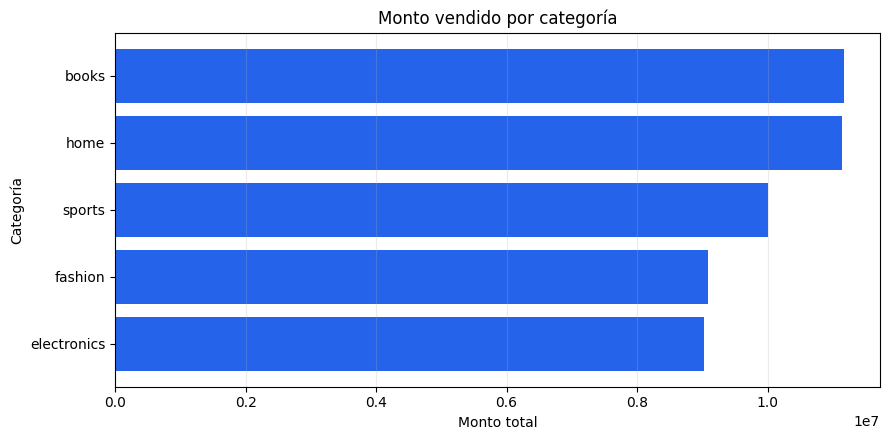

Respuesta: books es la categoría con mayor monto vendido (11,165,281.86).


In [0]:
category_sales = (spark.table(daily)
    .groupBy("category")
    .agg(F.sum("total_amount").alias("total_amount"))
    .orderBy(F.desc("total_amount")))

plot_data = category_sales.toPandas().sort_values("total_amount")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_data["category"], plot_data["total_amount"], color="#2563eb")
ax.set_title("Monto vendido por categoría")
ax.set_xlabel("Monto total")
ax.set_ylabel("Categoría")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

leader = category_sales.first()
print(f"Respuesta: {leader.category} es la categoría con mayor monto vendido ({leader.total_amount:,.2f}).")

## Consigna 1 — Evolución temporal

**Pregunta:** ¿Qué día tuvo el mayor monto vendido y ese día también fue el de mayor cantidad de transacciones?

Construí una visualización temporal que permita comparar ambas métricas sin ocultar sus unidades. Explicá si los dos máximos coinciden y qué implica que coincidan —o no— sobre el ticket promedio. Fuente sugerida: `gold_daily_sales`.

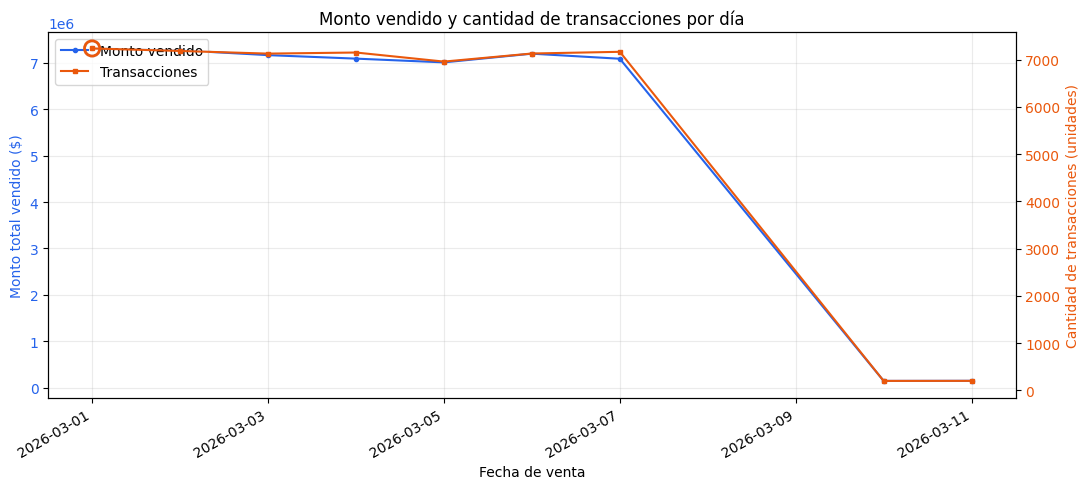

Día de mayor monto: 2026-03-01 ($7,310,840.77, 7,236 transacciones, ticket promedio $1,010.34).
Día de más transacciones: 2026-03-01 (7,236 transacciones, ticket promedio $1,010.34).


In [0]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pyspark.sql import functions as F

# 1) Agregar por sale_date ANTES de pasar a Pandas
daily_sales = (spark.table(daily)
    .groupBy("sale_date")
    .agg(
        F.sum("total_amount").cast("double").alias("total_amount"),
        F.sum("transaction_count").alias("transaction_count"),
    )
    .orderBy("sale_date"))

plot_data = daily_sales.toPandas()
plot_data["sale_date"] = pd.to_datetime(plot_data["sale_date"])
plot_data["avg_ticket"] = plot_data["total_amount"] / plot_data["transaction_count"]

# 2) Días máximos de cada métrica
top_amount = plot_data.loc[plot_data["total_amount"].idxmax()]
top_trans = plot_data.loc[plot_data["transaction_count"].idxmax()]

# 3) Gráfico de líneas con doble eje Y
c_amount, c_trans = "#2563eb", "#ea580c"
fig, ax1 = plt.subplots(figsize=(11, 5))

l1, = ax1.plot(plot_data["sale_date"], plot_data["total_amount"],
               color=c_amount, marker="o", markersize=3, label="Monto vendido")
ax1.set_xlabel("Fecha de venta")
ax1.set_ylabel("Monto total vendido ($)", color=c_amount)
ax1.tick_params(axis="y", labelcolor=c_amount)
ax1.grid(alpha=0.25)

ax2 = ax1.twinx()
l2, = ax2.plot(plot_data["sale_date"], plot_data["transaction_count"],
               color=c_trans, marker="s", markersize=3, label="Transacciones")
ax2.set_ylabel("Cantidad de transacciones (unidades)", color=c_trans)
ax2.tick_params(axis="y", labelcolor=c_trans)

# Marcar los máximos
ax1.scatter(top_amount["sale_date"], top_amount["total_amount"],
            s=120, facecolors="none", edgecolors=c_amount, linewidths=2, zorder=5)
ax2.scatter(top_trans["sale_date"], top_trans["transaction_count"],
            s=120, facecolors="none", edgecolors=c_trans, linewidths=2, zorder=5)

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
fig.autofmt_xdate()
ax1.set_title("Monto vendido y cantidad de transacciones por día")
ax1.legend(handles=[l1, l2], loc="upper left")
fig.tight_layout()
plt.show()

# 4) Respuesta escrita
coinciden = top_amount["sale_date"] == top_trans["sale_date"]
print(f"Día de mayor monto: {top_amount['sale_date']:%Y-%m-%d} "
      f"(${top_amount['total_amount']:,.2f}, {int(top_amount['transaction_count']):,} transacciones, "
      f"ticket promedio ${top_amount['avg_ticket']:,.2f}).")
print(f"Día de más transacciones: {top_trans['sale_date']:%Y-%m-%d} "
      f"({int(top_trans['transaction_count']):,} transacciones, "
      f"ticket promedio ${top_trans['avg_ticket']:,.2f}).")

Como se puede ver en la respuesta, el día de mayor monto vendido coincide con el día de mayor cantidad de transacciones (2026-03-01).
El hecho de que el máximo monto vendido coincida con el día de mayor cantidad de transacciones implica que el máximo de ventas está explicado por el volumen de las mismas y no tanto por un ticket que fue casualmente alto.

## Consigna 2 — Canal y fraude

**Pregunta:** ¿Qué canal de pago presenta la mayor tasa de fraude? ¿La conclusión se sostiene al considerar el número de transacciones de cada canal?

Mostrá tasa y volumen de manera legible. No compares sólo cantidades de fraude: calculá el denominador correcto. Fuente sugerida: `gold_daily_sales`.

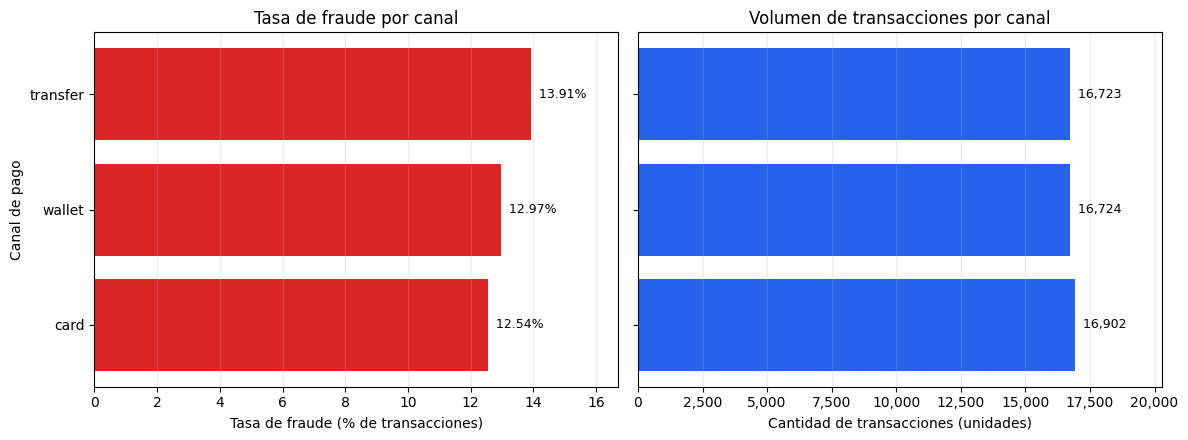

payment_channel  transaction_count  fraud_transactions  tasa_%
       transfer            16723.0              2327.0  13.915
         wallet            16724.0              2169.0  12.969
           card            16902.0              2119.0  12.537


In [0]:
# Tu solución. Recalculá la tasa global como suma(fraud_transactions) / suma(transaction_count).
# Evitá promediar directamente fraud_rate entre grupos.

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1) Agregar por canal ANTES de pasar a Pandas
channel_stats = (spark.table(daily)
    .groupBy("payment_channel")
    .agg(
        F.sum("fraud_transactions").alias("fraud_transactions"),
        F.sum("transaction_count").alias("transaction_count"),
    ))

df = channel_stats.toPandas()
df["fraud_transactions"] = df["fraud_transactions"].astype(float)
df["transaction_count"] = df["transaction_count"].astype(float)

# 2) Tasa de fraude con el denominador correcto
df["fraud_rate"] = df["fraud_transactions"] / df["transaction_count"]
df = df.sort_values("fraud_rate").reset_index(drop=True)

# 3) Visualización: tasa y volumen, mismo orden de canales
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ax1.barh(df["payment_channel"], df["fraud_rate"] * 100, color="#dc2626")
for i, r in df.iterrows():
    ax1.text(r["fraud_rate"] * 100, i, f"  {r['fraud_rate']*100:.2f}%", va="center", fontsize=9)
ax1.set_title("Tasa de fraude por canal")
ax1.set_xlabel("Tasa de fraude (% de transacciones)")
ax1.set_ylabel("Canal de pago")
ax1.grid(axis="x", alpha=0.25)
ax1.set_xlim(0, df["fraud_rate"].max() * 100 * 1.2)

ax2.barh(df["payment_channel"], df["transaction_count"], color="#2563eb")
for i, r in df.iterrows():
    ax2.text(r["transaction_count"], i, f"  {int(r['transaction_count']):,}", va="center", fontsize=9)
ax2.set_title("Volumen de transacciones por canal")
ax2.set_xlabel("Cantidad de transacciones (unidades)")
ax2.grid(axis="x", alpha=0.25)
ax2.set_xlim(0, df["transaction_count"].max() * 1.2)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

fig.tight_layout()
plt.show()

# 4) Tabla resumen
resumen = df.sort_values("fraud_rate", ascending=False)[
    ["payment_channel", "transaction_count", "fraud_transactions", "fraud_rate"]
].copy()
resumen["fraud_rate"] = (resumen["fraud_rate"] * 100).round(3)
resumen = resumen.rename(columns={"fraud_rate": "tasa_%"})
print(resumen.to_string(index=False))

# 5) Respuesta escrita
top_rate = df.loc[df["fraud_rate"].idxmax()]
top_count = df.loc[df["fraud_transactions"].idxmax()]
low_rate = df.loc[df["fraud_rate"].idxmin()]

El canal con mayor tasa de fraude es 'transfer'. 
La conclusión se sostiene al considerar transacciones totales ya que los volumenes de los canales son similares.

## Consigna 3 — Concentración geográfica y de producto

**Pregunta:** ¿Qué combinación de país y categoría genera el mayor monto? ¿Existe una categoría dominante en todos los países o cambia según el mercado?

Elegí una visualización que permita comparar simultáneamente países y categorías. Justificá brevemente por qué ese tipo de gráfico es adecuado. Fuente sugerida: `gold_daily_sales`.

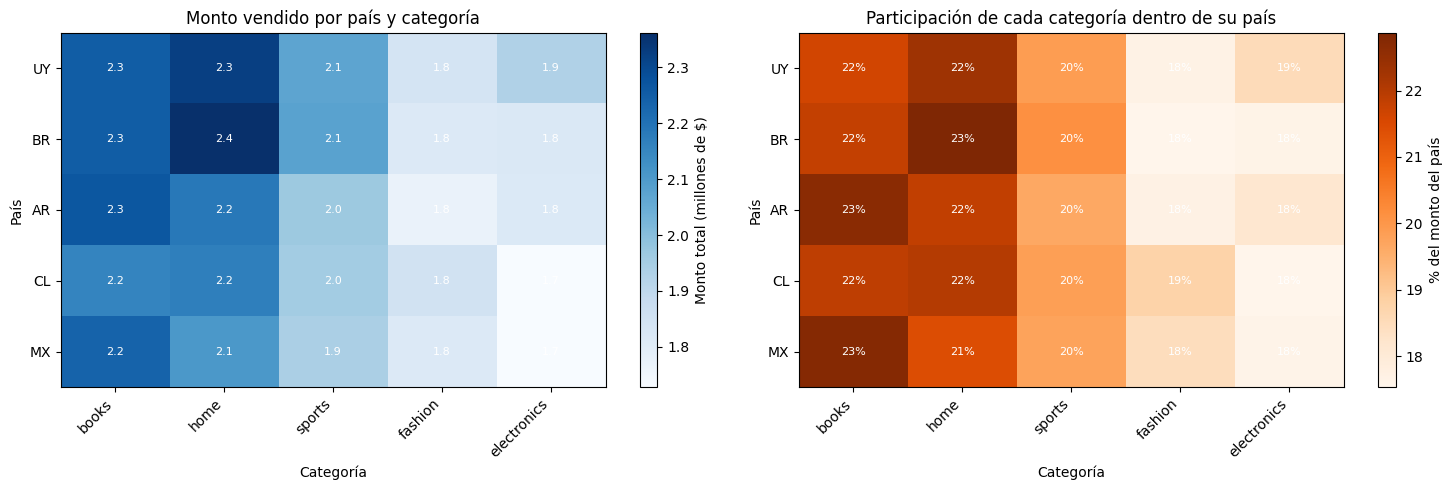

Mayor monto: BR - home ($2,361,959.97).

Categoría líder por país:
  UY: home (22.3% del monto del país)
  BR: home (22.9% del monto del país)
  AR: books (22.7% del monto del país)
  CL: home (22.0% del monto del país)
  MX: books (22.8% del monto del país)


In [0]:
# Tu solución. Algunas opciones: mapa de calor o barras agrupadas.
# La conclusión debe mencionar tanto el máximo global como las diferencias entre países.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1) Agregar por país y categoría ANTES de pasar a Pandas
pc_sales = (spark.table(daily)
    .groupBy("country", "category")
    .agg(F.sum("total_amount").cast("double").alias("total_amount")))

df = pc_sales.toPandas()

# 2) Matriz país x categoría (ordenada de mayor a menor monto)
matrix = df.pivot(index="country", columns="category", values="total_amount").fillna(0)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index,
                    matrix.sum(axis=0).sort_values(ascending=False).index]

# Participación de cada categoría dentro de su país (cada fila suma 100%)
share = matrix.div(matrix.sum(axis=1), axis=0) * 100

# 3) Heatmaps
def heatmap(ax, data, title, cbar_label, fmt, cmap):
    im = ax.imshow(data.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels(data.columns, rotation=45, ha="right")
    ax.set_yticks(range(data.shape[0]))
    ax.set_yticklabels(data.index)
    ax.set_title(title)
    ax.set_xlabel("Categoría")
    ax.set_ylabel("País")
    vmax = data.values.max()
    for i in range(data.shape[0]):
        for j in range(data.shape[1]):
            v = data.values[i, j]
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=8,
                    color="white" if v > vmax * 0.6 else "black")
    plt.colorbar(im, ax=ax, label=cbar_label)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, max(4, 0.6 * len(matrix) + 2)))
heatmap(ax1, matrix / 1e6, "Monto vendido por país y categoría",
        "Monto total (millones de $)", lambda v: f"{v:,.1f}", "Blues")
heatmap(ax2, share, "Participación de cada categoría dentro de su país",
        "% del monto del país", lambda v: f"{v:.0f}%", "Oranges")
fig.tight_layout()
plt.show()

# 4) Resultados
best = df.loc[df["total_amount"].idxmax()]
leader_by_country = share.idxmax(axis=1)
leader_share = share.max(axis=1)

print(f"Mayor monto: {best['country']} - {best['category']} (${best['total_amount']:,.2f}).\n")
print("Categoría líder por país:")
for c in matrix.index:
    print(f"  {c}: {leader_by_country[c]} ({leader_share[c]:.1f}% del monto del país)")

Mayor monto: BR - home ($2,361,959.97).

Categoría líder por país:
  UY: home (22.3% del monto del país)
  BR: home (22.9% del monto del país)
  AR: books (22.7% del monto del país)
  CL: home (22.0% del monto del país)
  MX: books (22.8% del monto del país)

No hay una categoría dominante en todos los países. El liderazgo cambia según el mercado (home, books), por lo que la mezcla de producto depende del país.
La combinación de mayor monto es BR - home.

## Consigna 4 — Calidad del pipeline

**Pregunta:** ¿Qué proporción de cada lote fue aceptada y rechazada? ¿El lote nuevo presenta una calidad diferente del lote inicial?

Compará lotes usando proporciones además de cantidades absolutas. Señalá cualquier limitación de comparar lotes de tamaños distintos. Fuente sugerida: `gold_batch_summary`.

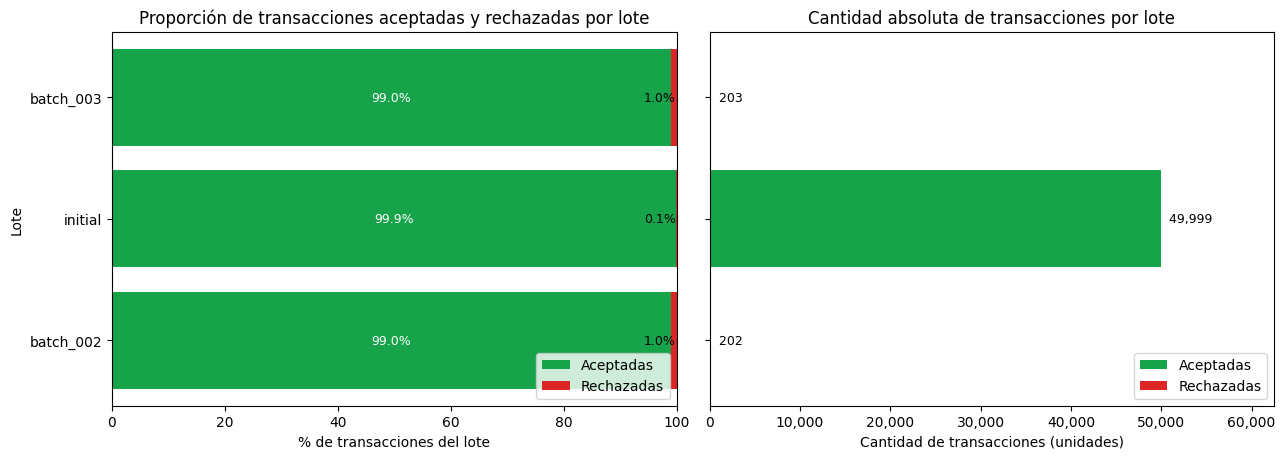

    batch   total  accepted  rejected  accepted_pct  rejected_pct
batch_002   202.0     200.0       2.0         99.01          0.99
  initial 49999.0   49948.0      51.0         99.90          0.10
batch_003   203.0     201.0       2.0         99.01          0.99

Lote inicial (batch_002): 0.99% rechazadas sobre 202 transacciones.
Lote nuevo   (batch_003): 0.99% rechazadas sobre 203 transacciones.
Diferencia: -0.00 puntos porcentuales (IC 95%: -1.93 a +1.92), z = -0.00, p = 0.996.

Respuesta: no hay evidencia suficiente de una diferencia de calidad: la tasa de rechazo pasó de 0.99% a 0.99%, pero la diferencia es compatible con variación aleatoria.
Limitación: los lotes tienen tamaños distintos (202 vs 203 transacciones), por eso comparo proporciones y no cantidades absolutas, y el lote más chico tiene una estimación más incierta.


In [0]:
# Tu solución. Calculá total = accepted_transactions + rejected_transactions.
# Un gráfico de barras apiladas al 100% puede facilitar la comparación de proporciones.

import pandas as pd
import matplotlib.pyplot as plt
from math import sqrt, erfc
from pyspark.sql import functions as F

batch_table = "workspace.bigdata_elianacoumroglon.gold_batch_summary"

# Opcional: si sabés cómo se llaman los lotes, fijalos acá (si no, usa el más antiguo y el más reciente)
initial_batch = None   # ej. "initial"
new_batch     = None   # ej. "incremental"

# 1) Agregar por lote ANTES de pasar a Pandas
batch_stats = (spark.table(batch_table)
    .groupBy("source_batch_id")
    .agg(F.sum("accepted_transactions").cast("double").alias("accepted"),
         F.sum("rejected_transactions").cast("double").alias("rejected"),
         F.sum("fraud_transactions").cast("double").alias("fraud"),
         F.min("refreshed_at").alias("first_refresh"))
    .orderBy("first_refresh"))

df = batch_stats.toPandas().rename(columns={"source_batch_id": "batch"})
df["batch"] = df["batch"].astype(str)

# 2) Proporciones con el denominador correcto (total de transacciones del lote)
df["total"] = df["accepted"] + df["rejected"]
df["accepted_pct"] = df["accepted"] / df["total"] * 100
df["rejected_pct"] = df["rejected"] / df["total"] * 100

# 3) Visualización: proporciones (100% apiladas) + cantidades absolutas
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, max(3.5, 0.9 * len(df) + 2)), sharey=True)

ax1.barh(df["batch"], df["accepted_pct"], color="#16a34a", label="Aceptadas")
ax1.barh(df["batch"], df["rejected_pct"], left=df["accepted_pct"], color="#dc2626", label="Rechazadas")
for i, r in df.iterrows():
    ax1.text(r["accepted_pct"] / 2, i, f"{r['accepted_pct']:.1f}%", ha="center", va="center",
             color="white", fontsize=9)
    ax1.text(min(r["accepted_pct"] + r["rejected_pct"] / 2, 97), i, f"{r['rejected_pct']:.1f}%",
             ha="center", va="center", color="white" if r["rejected_pct"] > 4 else "black", fontsize=9)
ax1.set_title("Proporción de transacciones aceptadas y rechazadas por lote")
ax1.set_xlabel("% de transacciones del lote")
ax1.set_ylabel("Lote")
ax1.set_xlim(0, 100)
ax1.legend(loc="lower right")

ax2.barh(df["batch"], df["accepted"], color="#16a34a", label="Aceptadas")
ax2.barh(df["batch"], df["rejected"], left=df["accepted"], color="#dc2626", label="Rechazadas")
for i, r in df.iterrows():
    ax2.text(r["total"], i, f"  {int(r['total']):,}", va="center", fontsize=9)
ax2.set_title("Cantidad absoluta de transacciones por lote")
ax2.set_xlabel("Cantidad de transacciones (unidades)")
ax2.set_xlim(0, df["total"].max() * 1.25)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax2.legend(loc="lower right")

fig.tight_layout()
plt.show()

# 4) Tabla resumen
print(df[["batch", "total", "accepted", "rejected", "accepted_pct", "rejected_pct"]]
      .round(2).to_string(index=False))

# 5) Lote inicial vs lote nuevo: test de dos proporciones sobre la tasa de rechazo
if initial_batch and new_batch:
    first = df[df["batch"] == initial_batch].iloc[0]
    last = df[df["batch"] == new_batch].iloc[0]
else:
    first, last = df.iloc[0], df.iloc[-1]

n1, x1 = first["total"], first["rejected"]
n2, x2 = last["total"], last["rejected"]
p1, p2 = x1 / n1, x2 / n2

p_pool = (x1 + x2) / (n1 + n2)
se_pool = sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
z = (p2 - p1) / se_pool
p_value = erfc(abs(z) / sqrt(2))

se_diff = sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
diff_pp = (p2 - p1) * 100
ci_low, ci_high = diff_pp - 1.96 * se_diff * 100, diff_pp + 1.96 * se_diff * 100

print(f"\nLote inicial ({first['batch']}): {p1*100:.2f}% rechazadas sobre {int(n1):,} transacciones.")
print(f"Lote nuevo   ({last['batch']}): {p2*100:.2f}% rechazadas sobre {int(n2):,} transacciones.")
print(f"Diferencia: {diff_pp:+.2f} puntos porcentuales (IC 95%: {ci_low:+.2f} a {ci_high:+.2f}), "
      f"z = {z:.2f}, p = {p_value:.4g}.")

# 6) Respuesta escrita
if p_value < 0.05:
    sentido = "peor" if p2 > p1 else "mejor"
    print(f"\nRespuesta: sí, el lote nuevo tiene una calidad {sentido} que el inicial: su tasa de rechazo "
          f"pasó de {p1*100:.2f}% a {p2*100:.2f}% y la diferencia es estadísticamente significativa.")
else:
    print(f"\nRespuesta: no hay evidencia suficiente de una diferencia de calidad: la tasa de rechazo pasó de "
          f"{p1*100:.2f}% a {p2*100:.2f}%, pero la diferencia es compatible con variación aleatoria.")
print(f"Limitación: los lotes tienen tamaños distintos ({int(n1):,} vs {int(n2):,} transacciones), por eso "
      "comparo proporciones y no cantidades absolutas, y el lote más chico tiene una estimación más incierta.")

## Criterios de entrega

Para cada consigna entregá: (1) la transformación de datos, (2) un gráfico, y (3) una conclusión de dos o tres oraciones que responda explícitamente la pregunta.

Cada gráfico debe tener título informativo, ejes y unidades legibles, categorías ordenadas cuando corresponda y una elección de color que no sea la única forma de comunicar el significado. No conviertas una tabla Silver completa a Pandas: agregá primero con Spark y convertí sólo el resultado pequeño.